# 07 — Financial Data Validation

**FinRAG learning series · Notebook 7 of 14**

## Learning objectives
1. Use **accounting identities** to check extracted values automatically.
2. Understand FinRAG's validation statuses and why automation can never mark a value *verified*.
3. See unit, currency and consolidated/standalone handling on real stored documents.
4. Detect duplicates and conflicts; understand confidence and human verification.

## Prerequisites
Notebook 06. For sections 4–6: the FinRAG database running with at least one processed document (saved outputs: two public annual
reports processed by the application).

## Concept
Extraction can fail silently (a misaligned column, an OCR digit). Financial statements contain **redundancy**: totals equal the sum of
their parts. FinRAG exploits that redundancy:

| Status | Set by | Meaning |
|---|---|---|
| `unvalidated` | automation | no check applies (e.g. inventories alone) |
| `validated` | automation | took part in at least one passing identity, none failed |
| `failed_validation` | automation | a hard identity failed or a sign is impossible |
| `needs_review` | automation | soft mismatch, conflicting values, OCR, ambiguous sub-columns |
| `verified` / `rejected` | **a person** | human decision, recorded in the audit log |

Checks run per (basis, column, unit) group and only when *all* inputs exist — nothing is filled in.

In [1]:
# Setup: make the production backend importable and keep secrets out of outputs
import sys, os
sys.path.insert(0, os.path.abspath("."))      # run notebooks from the notebooks/ folder
import finrag_nb as nb                          # helper: paths, safe settings, DB session
print("Backend package:", nb.BACKEND_DIR)
print("Documents folder:", nb.DOCS_DIR)

Backend package: /home/user/Ready_To_Deploy/backend
Documents folder: /opt/finrag_testdocs


In [2]:
import pymupdf, tempfile
from app.document_processing.parsers.pdf_parser import PdfParser
from app.financial_analytics.metric_extractor import extract_metrics

REPORT = "RIL-Integrated-Annual-Report-2024-25.pdf"     # any financial-statement PDF of yours
FIRST, LAST = 99, 100                                    # 1-based pages of the statements
src = pymupdf.open(nb.doc_path(REPORT))
sub = pymupdf.open(); sub.insert_pdf(src, from_page=FIRST - 1, to_page=LAST - 1)
tmp = tempfile.NamedTemporaryFile(suffix=".pdf", delete=False).name; sub.save(tmp)
parsed = PdfParser().parse(tmp)
metrics = extract_metrics(parsed.elements, "pdf", doc_currency=None, doc_unit=None)
print(len(parsed.elements), "elements ->", len(metrics), "canonical metric values")

142 elements -> 68 canonical metric values


## 1. Run the validator

In [3]:
import pandas as pd
from collections import Counter
from app.financial_analytics.validation import CHECKS, validate_metrics

statuses, notes, duplicates, checks = validate_metrics(metrics)
print("status counts:", dict(Counter(statuses)))
pd.DataFrame(checks)[["description", "period", "lhs", "rhs", "difference", "result"]]

status counts: {'validated': 44, 'unvalidated': 24}


,description,period,lhs,rhs,difference,result
0,Total assets = Total equity and liabilities,"As at 31st March, 2025",1950121,1950121,0,passed
1,Total assets = Total equity + Total liabilities,"As at 31st March, 2025",1950121,1950121,0,passed
2,Total assets = Current + Non-current assets,"As at 31st March, 2025",1950121,1950121,0,passed
3,Total liabilities = Current + Non-current liab...,"As at 31st March, 2025",940495,940495,0,passed
4,Total equity = Share capital + Other equity + NCI,"As at 31st March, 2025",1009626,1009626,0,passed
5,Total assets = Total equity and liabilities,"As at 31st March, 2024",1755986,1755986,0,passed
6,Total assets = Total equity + Total liabilities,"As at 31st March, 2024",1755986,1755986,0,passed
7,Total assets = Current + Non-current assets,"As at 31st March, 2024",1755986,1755986,0,passed
8,Total liabilities = Current + Non-current liab...,"As at 31st March, 2024",830198,830198,0,passed
9,Total equity = Share capital + Other equity + NCI,"As at 31st March, 2024",925788,925788,0,passed


## 2. Which identities exist?

In [4]:
for c in CHECKS:
    print(f"{'hard' if c.hard else 'soft'} | {c.description}")

hard | Total assets = Total equity and liabilities
hard | Total assets = Total equity + Total liabilities
hard | Total assets = Current + Non-current assets
hard | Total liabilities = Current + Non-current liabilities
soft | Total equity = Share capital + Other equity + NCI
soft | Total equity = Share capital + Other equity
hard | Total income = Revenue from operations + Other income
hard | Net profit = attributable to owners + to NCI
soft | Profit before tax = Total income - Total expenses (differs if exceptional items exist)
soft | Profit after tax = PBT - Current tax - Deferred tax


*Hard* identities must hold in any correct balance sheet / P&L. *Soft* ones can legitimately differ (e.g. exceptional items between
total expenses and profit before tax), so a mismatch means *needs review*, not *wrong*.

## 3. Experiment: corrupt one value in a copy
To see the validator catch an error we change **one** extracted value in a copy of the list (simulating a misread digit) — the data in
the document and database is untouched.

In [5]:
import copy
from decimal import Decimal

corrupted = copy.deepcopy(metrics)
victim = next(m for m in corrupted if m.metric_key == "total_equity" and "2025" in (m.period_label or ""))
print("original total equity:", victim.raw_value)
victim.value = victim.value + Decimal(9000)     # simulated extraction error
st2, notes2, _, checks2 = validate_metrics(corrupted)
print("status counts after corruption:", dict(Counter(st2)))
for c in checks2:
    if c["result"] != "passed":
        print(f"  {c['result']:>7}: {c['description']} | {c['period']} | lhs {c['lhs']} vs rhs {c['rhs']} (diff {c['difference']})")
i = corrupted.index(victim)
print("status of the corrupted value:", st2[i])

original total equity: 10,09,626
status counts after corruption: {'validated': 38, 'unvalidated': 24, 'failed_validation': 3, 'needs_review': 3}
   failed: Total assets = Total equity + Total liabilities | As at 31st March, 2025 | lhs 1950121 vs rhs 1959121 (diff -9000)
  mismatch: Total equity = Share capital + Other equity + NCI | As at 31st March, 2025 | lhs 1018626 vs rhs 1009626 (diff 9000)
status of the corrupted value: failed_validation


The corrupted total equity takes part in two identities. The **hard** one (*assets = equity + liabilities*) failed, so the three
values in it became `failed_validation` and will not be used for ratios. The **soft** one (*equity = share capital + other equity +
NCI*) reported a mismatch, so its values became `needs_review`. Either way, the error is surfaced instead of flowing into analysis.

## 4. Units, currency and basis on stored documents
The application stores detected metadata with status, method and evidence. Reading it from the database:

In [6]:
from app.models import Document
db = nb.db_session()
user = nb.notebook_user(db)
docs = db.query(Document).filter(Document.owner_id == user.id, Document.file_format == "pdf", Document.status == "processed").all()
for d in docs:
    meta = d.doc_metadata or {}
    print(f"\n{d.original_filename}")
    for k in ("currency", "unit", "reporting_period"):
        f = meta.get(k, {})
        val = f.get("value", {}).get("label") if isinstance(f.get("value"), dict) else f.get("value")
        print(f"  {k:<17} status={f.get('status'):<13} value={val!s:<28} method: {nb.shorten(f.get('method', ''), 110)}")


RIL-Integrated-Annual-Report-2024-25.pdf
  currency          status=uncertain     value=None                         method: USD is stated in only 1 of 15 table unit statements; the other unit statements name no recognisable currency …
  unit              status=detected      value=crore                        method: unit statement, 22 occurrence(s); per-table units are detected separately
  reporting_period  status=detected      value=Year ended 31 March 2025     method: 'year ended <date>' phrase, 13 of 14 mentions

RIL-Financial-Highlights-10-years.pdf
  currency          status=uncertain     value=None                         method: no currency stated in table headers; currencies mentioned in text: USD×3, SGD×3
  unit              status=detected      value=crore                        method: unit statement, 1 occurrence(s); per-table units are detected separately
  reporting_period  status=not_detected  value=None                         method: no 'year/period/quarter ended <

Currency is **uncertain** for these reports: the unit lines say "(C in crore)" because the ₹ glyph is font-encoded, and the only
explicit currency codes appear in a few unrelated tables. FinRAG asks the user to confirm instead of guessing.

## 5. Consolidated vs standalone
Group companies publish both. They must never be mixed in one calculation.

In [7]:
from app.models import FinancialStatement
for d in docs:
    rows = db.query(FinancialStatement).filter_by(document_id=d.id).all()
    print(d.original_filename)
    for s in rows:
        print(f"   {s.statement_type:<16} basis={s.basis!s:<13} unit={s.unit}  page {s.location.get('page')}")

RIL-Integrated-Annual-Report-2024-25.pdf
   profit_and_loss  basis=None          unit=crore  page 5
   balance_sheet    basis=None          unit=crore  page 5
   balance_sheet    basis=standalone    unit=crore  page 57
   profit_and_loss  basis=standalone    unit=crore  page 58
   cash_flow        basis=standalone    unit=crore  page 60
   balance_sheet    basis=consolidated  unit=crore  page 99
   profit_and_loss  basis=consolidated  unit=crore  page 100
RIL-Financial-Highlights-10-years.pdf
   profit_and_loss  basis=None          unit=crore  page 1
   balance_sheet    basis=None          unit=crore  page 1
RIL-Integrated-Annual-Report-2023-24.pdf
   balance_sheet    basis=None          unit=percent  page 3
   profit_and_loss  basis=standalone    unit=crore  page 49
   profit_and_loss  basis=None          unit=crore  page 49
   profit_and_loss  basis=consolidated  unit=crore  page 49
   balance_sheet    basis=standalone    unit=crore  page 79
   balance_sheet    basis=consolidated  un

## 6. Validation results and confidence across stored documents

Note the statement list above is *descriptive*: values from highlights/summary pages (basis not detected) are also grouped, and one
such group even took its unit (`percent`) from a percentage row. Analytics therefore prefers validated values from statements whose
type and basis are explicit.

canonical values by status: {'needs_review': 292, 'validated': 235, 'failed_validation': 7, 'unvalidated': 246}


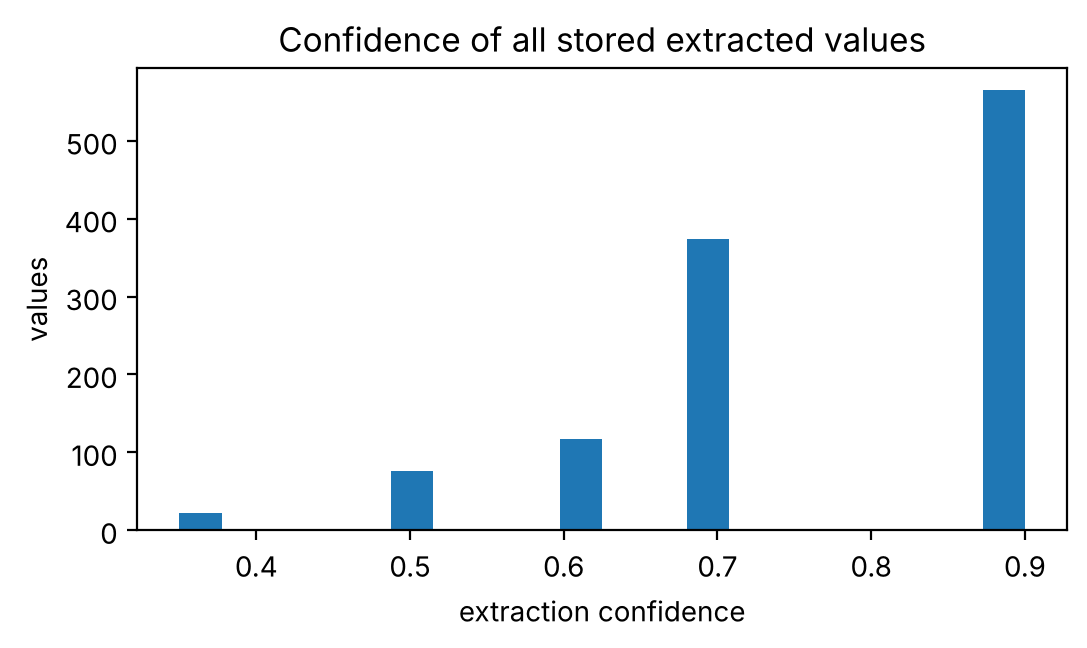

In [8]:
from sqlalchemy import func
from app.models import FinancialMetric
counts = (db.query(FinancialMetric.validation_status, func.count()).join(Document)
          .filter(Document.owner_id == user.id, FinancialMetric.metric_key != "line_item")
          .group_by(FinancialMetric.validation_status).all())
print("canonical values by status:", dict(counts))
conf = [c for (c,) in db.query(FinancialMetric.confidence).join(Document).filter(Document.owner_id == user.id).all()]
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3)); plt.hist(conf, bins=20); plt.xlabel("extraction confidence"); plt.ylabel("values")
plt.title("Confidence of all stored extracted values"); plt.show()

## 7. Human verification
Only a person can set `verified` or `rejected` — in the app (Document Analysis → ✓/✗) or via
`POST /api/metrics/{id}/verify` / `.../reject`. The decision, the previous status and the reviewer are stored in the metric's
notes and in the audit log. This notebook does not change any status.

In [9]:
verified = db.query(func.count(FinancialMetric.id)).join(Document).filter(Document.owner_id == user.id,
                                                                           FinancialMetric.validation_status == "verified").scalar()
print("values verified by a person so far:", verified)
db.close()

values verified by a person so far: 0


## Interpretation
* On the real statement pages every hard identity passed, so the participating values are `validated`.
* Corrupting a single value made the related identities fail — a concrete demonstration of why identities catch extraction errors.
* Stored documents show *uncertain* currency, detected units and explicit consolidated/standalone statements; values that need
  review are kept and labelled, never silently corrected.

## Common errors and troubleshooting
| Symptom | Cause | Fix |
|---|---|---|
| Many `unvalidated` values | No identity applies (e.g. notes, highlights) | Normal; verify important ones by hand |
| `needs_review` on good values | Same metric/period printed twice with different values in one table (sub-columns) | Check the source; verify or reject |
| Identity fails by a few units | Rounding in printed figures | Tolerance is 1 unit per addend or 0.05 %; larger gaps are real |
| Currency "uncertain" | No currency in table unit lines | Correct it in Document Analysis |

## Practical exercises
1. Corrupt a *current liabilities* value instead and predict which checks will fail before running.
2. Find a `needs_review` value in your own document and decide (in the app) whether to verify or reject it.
3. Write a new identity, e.g. *gross profit = revenue − cost of revenue*, as an `IdentityCheck` and test it.

## Summary
You validated real extractions with accounting identities, watched a simulated error get caught, inspected stored metadata, basis and
validation results, and learnt where human verification fits.

## Further learning
* FinRAG source: `backend/app/financial_analytics/validation.py`
* The accounting equation: https://www.ifrs.org/ (Conceptual Framework, chapter 4)
* Next: **08 — Embeddings**.